## Problem 14: Forecasting U.S. Industrial Production Growth Using Correlated Macroeconomic Indicators

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [3]:
series = [
    "INDPRO",
    "UNRATE",
    "PAYEMS",
    "TCU",
    "CPIAUCSL",
    "M2SL",
    "HOUST",
    "FEDFUNDS",
    "GS2",
    "GS10",
    "AAA",
    "BAA"
]

df = pd.DataFrame()

for series_id in series:

    url = (
        f"https://fred.stlouisfed.org/"
        f"graph/fredgraph.csv?id={series_id}"
    )

    temp = pd.read_csv(url)

    # Rename the first column to DATE
    temp = temp.rename(
        columns={
            temp.columns[0]: "DATE"
        }
    )

    # Convert DATE to datetime
    temp["DATE"] = pd.to_datetime(
        temp["DATE"]
    )

    temp = temp.set_index(
        "DATE"
    )

    if df.empty:
        df = temp
    else:
        df = df.join(
            temp,
            how="outer"
        )

In [4]:
for column in series:

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Restrict the period
    df = df.loc[
    "1970-01-01":"2026-07-01"
].copy()

df.head()

,INDPRO,UNRATE,PAYEMS,TCU,CPIAUCSL,M2SL,HOUST,FEDFUNDS,GS2,GS10,AAA,BAA
DATE,,,,,,,,,,,,
1970-01-01,37.9948,3.9,71176.0,83.6765,37.9,589.6,1085.0,8.98,NaN,7.79,7.91,8.86
1970-02-01,37.9698,4.2,71305.0,83.3607,38.1,586.3,1305.0,8.98,NaN,7.24,7.93,8.78
1970-03-01,37.9205,4.4,71451.0,82.9935,38.3,587.3,1319.0,7.76,NaN,7.07,7.84,8.63
1970-04-01,37.8230,4.6,71348.0,82.5235,38.5,588.4,1264.0,8.10,NaN,7.39,7.83,8.70
1970-05-01,37.7789,4.8,71124.0,82.1724,38.6,591.5,1290.0,7.95,NaN,7.91,8.11,8.98


In [5]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 679 entries, 1970-01-01 to 2026-07-01
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   INDPRO    679 non-null    float64
 1   UNRATE    678 non-null    float64
 2   PAYEMS    679 non-null    float64
 3   TCU       679 non-null    float64
 4   CPIAUCSL  678 non-null    float64
 5   M2SL      679 non-null    float64
 6   HOUST     679 non-null    float64
 7   FEDFUNDS  679 non-null    float64
 8   GS2       602 non-null    float64
 9   GS10      679 non-null    float64
 10  AAA       679 non-null    float64
 11  BAA       679 non-null    float64
dtypes: float64(12)
memory usage: 69.0 KB


In [6]:
df.isna().sum()

INDPRO       0
UNRATE       1
PAYEMS       0
TCU          0
CPIAUCSL     1
M2SL         0
HOUST        0
FEDFUNDS     0
GS2         77
GS10         0
AAA          0
BAA          0
dtype: int64

In [7]:
df.describe().round(2)

,INDPRO,UNRATE,PAYEMS,TCU,CPIAUCSL,M2SL,HOUST,FEDFUNDS,GS2,GS10,AAA,BAA
count,679.00,678.00,679.00,679.00,678.00,679.00,679.00,679.00,602.00,679.00,679.00,679.00
mean,75.97,6.04,117834.34,79.42,164.71,6882.46,1432.86,4.89,4.96,5.95,7.08,8.14
std,22.61,1.72,25715.51,3.95,78.74,6318.25,402.79,3.83,3.66,3.09,2.75,2.96
min,36.45,3.40,70409.00,64.08,37.90,586.30,478.00,0.05,0.12,0.62,2.14,3.16
25%,53.46,4.70,93293.00,76.77,102.68,2166.75,1184.50,1.68,1.74,3.67,5.11,5.94
50%,84.50,5.70,125445.00,79.46,162.10,4138.90,1450.00,4.91,4.61,5.81,7.15,8.02
75%,98.76,7.20,137283.00,82.31,228.68,9987.80,1682.50,6.78,7.11,7.81,8.69,9.82
max,104.10,14.80,158881.00,88.80,333.98,23218.00,2494.00,19.10,16.46,15.32,15.49,17.18


In [8]:
df = df.rename(columns={
    "INDPRO": "industrial_production",
    "UNRATE": "unemployment",
    "PAYEMS": "payrolls",
    "TCU": "capacity_utilisation",
    "CPIAUCSL": "cpi",
    "M2SL": "money_supply",
    "HOUST": "housing_starts",
    "FEDFUNDS": "fed_funds",
    "GS2": "treasury_2y",
    "GS10": "treasury_10y",
    "AAA": "aaa_yield",
    "BAA": "baa_yield"
})

df.head()

,industrial_production,unemployment,payrolls,capacity_utilisation,cpi,money_supply,housing_starts,fed_funds,treasury_2y,treasury_10y,aaa_yield,baa_yield
DATE,,,,,,,,,,,,
1970-01-01,37.9948,3.9,71176.0,83.6765,37.9,589.6,1085.0,8.98,NaN,7.79,7.91,8.86
1970-02-01,37.9698,4.2,71305.0,83.3607,38.1,586.3,1305.0,8.98,NaN,7.24,7.93,8.78
1970-03-01,37.9205,4.4,71451.0,82.9935,38.3,587.3,1319.0,7.76,NaN,7.07,7.84,8.63
1970-04-01,37.8230,4.6,71348.0,82.5235,38.5,588.4,1264.0,8.10,NaN,7.39,7.83,8.70
1970-05-01,37.7789,4.8,71124.0,82.1724,38.6,591.5,1290.0,7.95,NaN,7.91,8.11,8.98


**Current Industrial-Production Growth**

In [9]:
df["current_ip_growth"] = (
    100
    * (
        np.log(
            df["industrial_production"]
        )
        -
        np.log(
            df["industrial_production"].shift(12)
        )
    )
)

**Future Industrial-Production Growth**

In [10]:
df["future_ip_growth"] = (
    100
    * (
        np.log(
            df["industrial_production"].shift(-12)
        )
        -
        np.log(
            df["industrial_production"]
        )
    )
)

**Payroll Growth**

In [11]:
df["payroll_growth"] = (
    100
    * (
        np.log(
            df["payrolls"]
        )
        -
        np.log(
            df["payrolls"].shift(12)
        )
    )
)

**Inflation**

In [12]:
df["inflation"] = (
    100
    * (
        np.log(
            df["cpi"]
        )
        -
        np.log(
            df["cpi"].shift(12)
        )
    )
)

**Money Supply Growth**

In [13]:
df["money_growth"] = (
    100
    * (
        np.log(
            df["money_supply"]
        )
        -
        np.log(
            df["money_supply"].shift(12)
        )
    )
)

**Housing-Start Growth**

In [14]:
df["housing_growth"] = (
    100
    * (
        np.log(
            df["housing_starts"]
        )
        -
        np.log(
            df["housing_starts"].shift(12)
        )
    )
)

In [15]:
df["term_spread"] = (
    df["treasury_10y"]
    -
    df["treasury_2y"]
)

In [16]:
df["default_spread"] = (
    df["baa_yield"]
    -
    df["aaa_yield"]
)

In [17]:
features = [
    "current_ip_growth",
    "unemployment",
    "payroll_growth",
    "capacity_utilisation",
    "inflation",
    "money_growth",
    "housing_growth",
    "fed_funds",
    "treasury_2y",
    "treasury_10y",
    "term_spread",
    "default_spread"
]

print(
    "Number of candidate predictors:",
    len(features)
)

Number of candidate predictors: 12


**Final Modelling Dataset**

In [18]:
model_df = df[
    features
    + ["future_ip_growth"]
].copy()

model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

model_df = model_df.dropna()

model_df.head()

,current_ip_growth,unemployment,payroll_growth,capacity_utilisation,inflation,money_growth,housing_growth,fed_funds,treasury_2y,treasury_10y,term_spread,default_spread,future_ip_growth
DATE,,,,,,,,,,,,,
1976-06-01,8.757874,7.6,3.663084,79.3919,5.809256,11.243821,31.870460,5.48,7.06,7.86,0.80,1.27,8.807835
1976-07-01,8.283039,7.8,3.553410,79.6612,5.406722,10.799268,13.342943,5.31,6.85,7.83,0.98,1.26,8.367695
1976-08-01,7.989484,7.8,3.252931,80.0235,5.561972,11.117210,20.714321,5.29,6.63,7.77,1.14,1.19,7.781019
1976-09-01,7.051848,7.6,3.391364,80.1127,5.348868,11.361681,30.804300,5.25,6.42,7.59,1.17,1.02,7.847364
1976-10-01,6.582540,7.7,3.011958,79.8993,5.320404,11.998546,19.231609,5.02,5.98,7.41,1.43,0.97,8.018859


In [19]:
model_df.shape

(590, 13)

In [20]:
model_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 590 entries, 1976-06-01 to 2025-07-01
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   current_ip_growth     590 non-null    float64
 1   unemployment          590 non-null    float64
 2   payroll_growth        590 non-null    float64
 3   capacity_utilisation  590 non-null    float64
 4   inflation             590 non-null    float64
 5   money_growth          590 non-null    float64
 6   housing_growth        590 non-null    float64
 7   fed_funds             590 non-null    float64
 8   treasury_2y           590 non-null    float64
 9   treasury_10y          590 non-null    float64
 10  term_spread           590 non-null    float64
 11  default_spread        590 non-null    float64
 12  future_ip_growth      590 non-null    float64
dtypes: float64(13)
memory usage: 64.5 KB


In [21]:
model_df.describe().round(3)

,current_ip_growth,unemployment,payroll_growth,capacity_utilisation,inflation,money_growth,housing_growth,fed_funds,treasury_2y,treasury_10y,term_spread,default_spread,future_ip_growth
count,590.000,590.000,590.000,590.000,590.000,590.000,590.000,590.000,590.000,590.000,590.000,590.000,590.000
mean,1.763,6.074,1.439,79.120,3.565,6.219,0.076,4.663,4.983,5.835,0.852,1.054,1.638
std,4.328,1.762,2.295,3.760,2.588,3.714,20.663,3.945,3.691,3.266,0.918,0.432,4.248
min,-19.017,3.400,-14.376,64.085,-1.978,-4.751,-79.401,0.050,0.120,0.620,-2.130,0.550,-19.017
25%,-0.132,4.700,0.787,76.762,1.993,4.276,-8.739,1.160,1.662,3.290,0.180,0.760,-0.132
50%,2.293,5.750,1.694,79.312,2.925,6.051,1.669,4.740,4.670,5.160,0.795,0.940,2.197
75%,4.223,7.200,2.532,82.008,4.239,7.934,11.752,6.575,7.148,7.945,1.470,1.207,4.015
max,15.317,14.800,10.308,86.649,13.621,23.726,67.391,19.100,16.460,15.320,2.830,3.380,15.317


**Plot: Future Industrial-Production Growth**

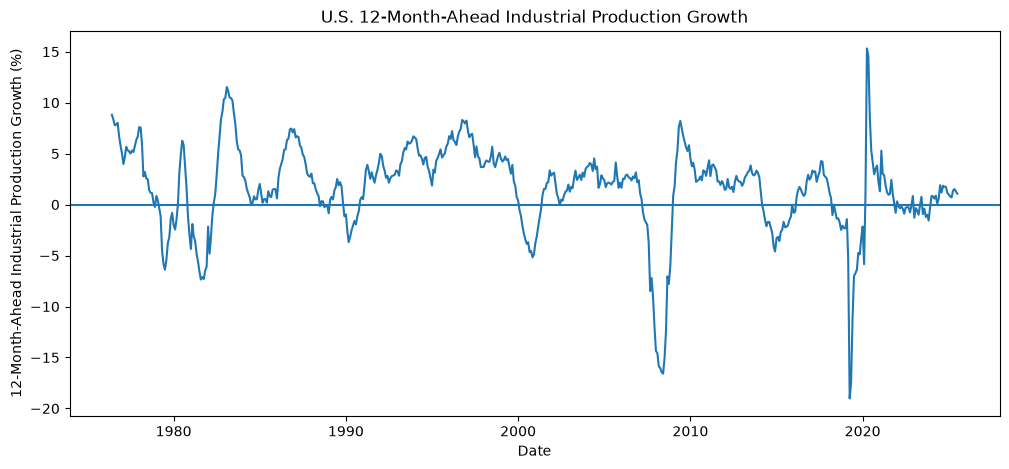

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    model_df.index,
    model_df["future_ip_growth"]
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "12-Month-Ahead Industrial Production Growth (%)"
)

plt.title(
    "U.S. 12-Month-Ahead Industrial Production Growth"
)

plt.show()

In [23]:
correlation_matrix = (
    model_df[features]
    .corr()
)

correlation_matrix.round(2)

,current_ip_growth,unemployment,payroll_growth,capacity_utilisation,inflation,money_growth,housing_growth,fed_funds,treasury_2y,treasury_10y,term_spread,default_spread
current_ip_growth,1.00,-0.21,0.75,0.67,0.13,-0.16,0.36,0.14,0.18,0.18,-0.07,-0.53
unemployment,-0.21,1.00,-0.44,-0.41,0.03,0.38,0.11,0.10,0.15,0.30,0.45,0.52
payroll_growth,0.75,-0.44,1.00,0.69,0.30,-0.27,0.19,0.22,0.25,0.21,-0.28,-0.38
capacity_utilisation,0.67,-0.41,0.69,1.00,0.40,-0.24,0.00,0.45,0.46,0.40,-0.43,-0.44
inflation,0.13,0.03,0.30,0.40,1.00,0.09,-0.21,0.70,0.66,0.60,-0.51,0.22
money_growth,-0.16,0.38,-0.27,-0.24,0.09,1.00,0.15,0.03,0.03,0.05,0.05,0.28
housing_growth,0.36,0.11,0.19,0.00,-0.21,0.15,1.00,-0.19,-0.15,-0.11,0.20,-0.30
fed_funds,0.14,0.10,0.22,0.45,0.70,0.03,-0.19,1.00,0.97,0.92,-0.64,0.32
treasury_2y,0.18,0.15,0.25,0.46,0.66,0.03,-0.15,0.97,1.00,0.97,-0.56,0.32
treasury_10y,0.18,0.30,0.21,0.40,0.60,0.05,-0.11,0.92,0.97,1.00,-0.35,0.36


**Plot: Correlation Matrix**

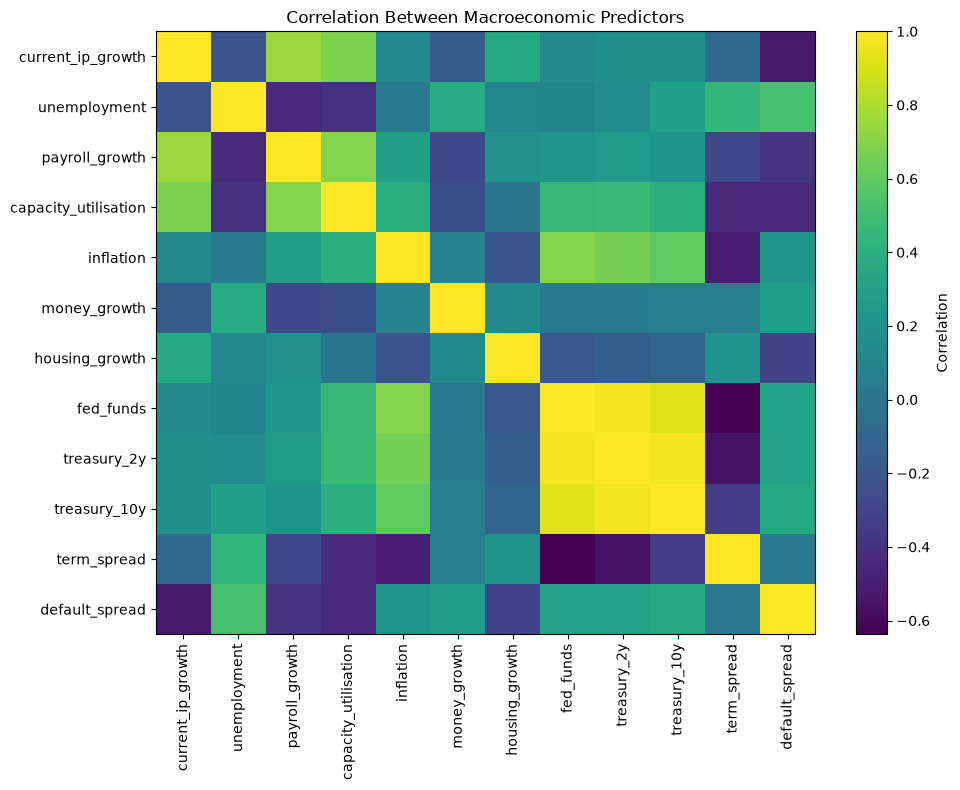

In [24]:
plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(features)),
    features,
    rotation=90
)

plt.yticks(
    range(len(features)),
    features
)

plt.title(
    "Correlation Between Macroeconomic Predictors"
)

plt.tight_layout()

plt.show()

In [25]:
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(
            correlation_matrix.shape
        ),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

correlation_pairs.head(10)

fed_funds          treasury_2y             0.974438
treasury_2y        treasury_10y            0.972500
fed_funds          treasury_10y            0.921967
current_ip_growth  payroll_growth          0.754037
inflation          fed_funds               0.696044
payroll_growth     capacity_utilisation    0.693163
current_ip_growth  capacity_utilisation    0.674508
inflation          treasury_2y             0.658711
fed_funds          term_spread            -0.637249
inflation          treasury_10y            0.602150
dtype: float64

**Define X and y**

In [26]:
X = model_df[features]

y = model_df[
    "future_ip_growth"
]

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

X_train = X_train.iloc[:-12]

y_train = y_train.iloc[:-12]

print(
    "Training observations:",
    len(X_train)
)

print(
    "Test observations:",
    len(X_test)
)

print()

print(
    "Training period:",
    X_train.index.min(),
    "to",
    X_train.index.max()
)

print()

print(
    "Test period:",
    X_test.index.min(),
    "to",
    X_test.index.max()
)

Training observations: 460
Test observations: 118

Training period: 1976-06-01 00:00:00 to 2014-09-01 00:00:00

Test period: 2015-10-01 00:00:00 to 2025-07-01 00:00:00


**Historical-Mean Benchmark**

In [28]:
historical_mean = (
    y_train.mean()
)

historical_mean_pred = np.repeat(
    historical_mean,
    len(y_test)
)

print(
    "Historical mean industrial production growth:",
    historical_mean
)

Historical mean industrial production growth: 2.1019968667947917


**Standardise the Predictors for OLS**

In [29]:
scaler = StandardScaler()

X_train_scaled = (
    scaler.fit_transform(
        X_train
    )
)

X_test_scaled = (
    scaler.transform(
        X_test
    )
)

In [30]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

ols_pred = ols.predict(
    X_test_scaled
)

ols_coefficients = pd.Series(
    ols.coef_,
    index=features,
    name="OLS"
)

ols_coefficients.round(4)

current_ip_growth      -1.0266
unemployment            2.2771
payroll_growth          0.0024
capacity_utilisation    0.9614
inflation              -1.5575
money_growth            0.2111
housing_growth          1.1957
fed_funds              -4.6094
treasury_2y             2.0540
treasury_10y            1.8909
term_spread            -1.8538
default_spread         -1.2063
Name: OLS, dtype: float64

In [31]:
alpha_values = np.logspace(-4,2,80)

In [32]:
ridge_alpha_values = np.logspace(
    -4,
    4,
    120
)

In [33]:
tscv = TimeSeriesSplit(
    n_splits=5,
    gap=12
)

**Ridge Model**

In [34]:
ridge_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge()
    )
])

ridge_grid = {
    "ridge__alpha":
    ridge_alpha_values
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defau

In [35]:
best_ridge_alpha = (
    ridge_search
    .best_params_[
        "ridge__alpha"
    ]
)

print(
    "Best Ridge alpha:",
    best_ridge_alpha
)

Best Ridge alpha: 2898.577214651062


In [36]:
best_ridge = (
    ridge_search
    .best_estimator_
)

ridge_pred = best_ridge.predict(
    X_test
)

In [37]:
ridge_coefficients = pd.Series(
    best_ridge
    .named_steps["ridge"]
    .coef_,
    index=features,
    name="Ridge"
)

ridge_coefficients.round(4)

current_ip_growth       0.0564
unemployment            0.1533
payroll_growth          0.0215
capacity_utilisation   -0.0456
inflation              -0.1579
money_growth            0.0074
housing_growth          0.2498
fed_funds              -0.0723
treasury_2y            -0.0162
treasury_10y            0.0074
term_spread             0.0866
default_spread         -0.0776
Name: Ridge, dtype: float64

**LASSO Model**

In [38]:
lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(
            max_iter=100000
        )
    )
])

lasso_grid = {
    "lasso__alpha":
    alpha_values
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

In [39]:
best_lasso_alpha = (
    lasso_search
    .best_params_[
        "lasso__alpha"
    ]
)

print(
    "Best LASSO alpha:",
    best_lasso_alpha
)

Best LASSO alpha: 1.5038869469554101


In [40]:
best_lasso = (
    lasso_search
    .best_estimator_
)

lasso_pred = best_lasso.predict(
    X_test
)

In [41]:
lasso_coefficients = pd.Series(
    best_lasso
    .named_steps["lasso"]
    .coef_,
    index=features,
    name="LASSO"
)

lasso_coefficients.round(4)

current_ip_growth       0.0000
unemployment            0.0000
payroll_growth          0.0000
capacity_utilisation    0.0000
inflation              -0.0000
money_growth            0.0000
housing_growth          0.4604
fed_funds              -0.0000
treasury_2y             0.0000
treasury_10y            0.0000
term_spread             0.0000
default_spread          0.0000
Name: LASSO, dtype: float64

**Elastic Net - Candidate l1_ratio Values**

In [42]:
l1_ratio_values = [0.10,0.25,0.50,0.75,0.90]

We deliberately avoid exactly 0 and exactly 1 because we already estimate pure Ridge and pure LASSO separately.

In [43]:
elastic_net_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "elastic_net",
        ElasticNet(
            max_iter=100000
        )
    )
])

In [44]:
elastic_net_grid = {
    "elastic_net__alpha":
        alpha_values,

    "elastic_net__l1_ratio":
        l1_ratio_values
}

In [45]:
elastic_net_search = GridSearchCV(
    estimator=elastic_net_pipeline,
    param_grid=elastic_net_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

elastic_net_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'elastic_net__alpha': array([1.0000...00000000e+02]), 'elastic_net__l1_ratio': [0.1, 0.25, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [46]:
best_elastic_alpha = (
    elastic_net_search
    .best_params_[
        "elastic_net__alpha"
    ]
)

best_l1_ratio = (
    elastic_net_search
    .best_params_[
        "elastic_net__l1_ratio"
    ]
)

print(
    "Best Elastic Net alpha:",
    best_elastic_alpha
)

print(
    "Best Elastic Net l1_ratio:",
    best_l1_ratio
)

Best Elastic Net alpha: 1.5038869469554101
Best Elastic Net l1_ratio: 0.9


In [47]:
best_elastic_net = (
    elastic_net_search
    .best_estimator_
)

elastic_net_pred = (
    best_elastic_net.predict(
        X_test
    )
)

In [48]:
elastic_net_coefficients = pd.Series(
    best_elastic_net
    .named_steps["elastic_net"]
    .coef_,
    index=features,
    name="Elastic_Net"
)

elastic_net_coefficients.round(4)

current_ip_growth       0.0000
unemployment            0.0000
payroll_growth         -0.0000
capacity_utilisation   -0.0000
inflation              -0.0000
money_growth           -0.0000
housing_growth          0.5309
fed_funds              -0.0000
treasury_2y            -0.0000
treasury_10y           -0.0000
term_spread             0.0000
default_spread         -0.0000
Name: Elastic_Net, dtype: float64

In [49]:
selected_elastic_features = (
    elastic_net_coefficients[
        elastic_net_coefficients != 0
    ]
)

selected_elastic_features

housing_growth    0.530927
Name: Elastic_Net, dtype: float64

In [50]:
eliminated_elastic_features = (
    elastic_net_coefficients[
        elastic_net_coefficients == 0
    ]
)

eliminated_elastic_features

current_ip_growth       0.0
unemployment            0.0
payroll_growth         -0.0
capacity_utilisation   -0.0
inflation              -0.0
money_growth           -0.0
fed_funds              -0.0
treasury_2y            -0.0
treasury_10y           -0.0
term_spread             0.0
default_spread         -0.0
Name: Elastic_Net, dtype: float64

In [51]:
print(
    "Total candidate predictors:",
    len(features)
)

print(
    "Elastic Net predictors selected:",
    len(
        selected_elastic_features
    )
)

print(
    "Elastic Net predictors eliminated:",
    len(
        eliminated_elastic_features
    )
)

Total candidate predictors: 12
Elastic Net predictors selected: 1
Elastic Net predictors eliminated: 11


**Compare Feature Selection with LASSO**

In [52]:
selected_lasso_features = (
    lasso_coefficients[
        lasso_coefficients != 0
    ]
)

print(
    "Predictors selected by LASSO:",
    len(
        selected_lasso_features
    )
)

print(
    "Predictors selected by Elastic Net:",
    len(
        selected_elastic_features
    )
)

Predictors selected by LASSO: 1
Predictors selected by Elastic Net: 1


**Full Coefficient Comparison**

In [53]:
coefficient_table = pd.DataFrame({
    "OLS":
        ols_coefficients,

    "Ridge":
        ridge_coefficients,

    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

coefficient_table[
    "LASSO_Selected"
] = (
    coefficient_table[
        "LASSO"
    ] != 0
)

coefficient_table[
    "ElasticNet_Selected"
] = (
    coefficient_table[
        "Elastic_Net"
    ] != 0
)

coefficient_table.round(4)

,OLS,Ridge,LASSO,Elastic_Net,LASSO_Selected,ElasticNet_Selected
current_ip_growth,-1.0266,0.0564,0.0000,0.0000,False,False
unemployment,2.2771,0.1533,0.0000,0.0000,False,False
payroll_growth,0.0024,0.0215,0.0000,-0.0000,False,False
capacity_utilisation,0.9614,-0.0456,0.0000,-0.0000,False,False
inflation,-1.5575,-0.1579,-0.0000,-0.0000,False,False
money_growth,0.2111,0.0074,0.0000,-0.0000,False,False
housing_growth,1.1957,0.2498,0.4604,0.5309,True,True
fed_funds,-4.6094,-0.0723,-0.0000,-0.0000,False,False
treasury_2y,2.0540,-0.0162,0.0000,-0.0000,False,False
treasury_10y,1.8909,0.0074,0.0000,-0.0000,False,False


In [54]:
def evaluate_model(
    y_true,
    y_pred
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mae, r2

In [55]:
mean_rmse, mean_mae, mean_r2 = evaluate_model(
    y_test,
    historical_mean_pred
)

ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test,
    ols_pred
)

ridge_rmse, ridge_mae, ridge_r2 = evaluate_model(
    y_test,
    ridge_pred
)

lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test,
    lasso_pred
)

elastic_rmse, elastic_mae, elastic_r2 = evaluate_model(
    y_test,
    elastic_net_pred
)

**Performance Table**

In [56]:
performance = pd.DataFrame({
    "Model": [
        "Historical Mean",
        "OLS",
        "Ridge",
        "LASSO",
        "Elastic Net"
    ],

    "RMSE": [
        mean_rmse,
        ols_rmse,
        ridge_rmse,
        lasso_rmse,
        elastic_rmse
    ],

    "MAE": [
        mean_mae,
        ols_mae,
        ridge_mae,
        lasso_mae,
        elastic_mae
    ],

    "R2": [
        mean_r2,
        ols_r2,
        ridge_r2,
        lasso_r2,
        elastic_r2
    ]
})

performance.round(4)

,Model,RMSE,MAE,R2
0,Historical Mean,4.4483,2.8342,-0.1992
1,OLS,3.6933,2.4994,0.1733
2,Ridge,4.3290,2.6662,-0.1358
3,LASSO,4.5045,2.8532,-0.2298
4,Elastic Net,4.5147,2.8591,-0.2353


In [57]:
def out_of_sample_r2(
    y_true,
    model_pred,
    benchmark_pred
):

    model_error = np.sum(
        (
            y_true.values
            - model_pred
        ) ** 2
    )

    benchmark_error = np.sum(
        (
            y_true.values
            - benchmark_pred
        ) ** 2
    )

    return (
        1
        -
        model_error
        / benchmark_error
    )

In [58]:
ols_oos_r2 = out_of_sample_r2(
    y_test,
    ols_pred,
    historical_mean_pred
)

ridge_oos_r2 = out_of_sample_r2(
    y_test,
    ridge_pred,
    historical_mean_pred
)

lasso_oos_r2 = out_of_sample_r2(
    y_test,
    lasso_pred,
    historical_mean_pred
)

elastic_oos_r2 = out_of_sample_r2(
    y_test,
    elastic_net_pred,
    historical_mean_pred
)

In [59]:
print(
    "OLS OOS R2:",
    round(
        ols_oos_r2,
        4
    )
)

print(
    "Ridge OOS R2:",
    round(
        ridge_oos_r2,
        4
    )
)

print(
    "LASSO OOS R2:",
    round(
        lasso_oos_r2,
        4
    )
)

print(
    "Elastic Net OOS R2:",
    round(
        elastic_oos_r2,
        4
    )
)

OLS OOS R2: 0.3106
Ridge OOS R2: 0.0529
LASSO OOS R2: -0.0255
Elastic Net OOS R2: -0.0301


In [60]:
elastic_vs_lasso_gain = (
    lasso_rmse
    - elastic_rmse
)

elastic_vs_lasso_percent = (
    elastic_vs_lasso_gain
    / lasso_rmse
    * 100
)

print(
    "Elastic Net RMSE improvement over LASSO:",
    round(
        elastic_vs_lasso_gain,
        4
    )
)

print(
    "Percentage improvement:",
    round(
        elastic_vs_lasso_percent,
        2
    ),
    "%"
)

Elastic Net RMSE improvement over LASSO: -0.0102
Percentage improvement: -0.23 %


**Plot: Actual vs Forecast Industrial Production Growth**

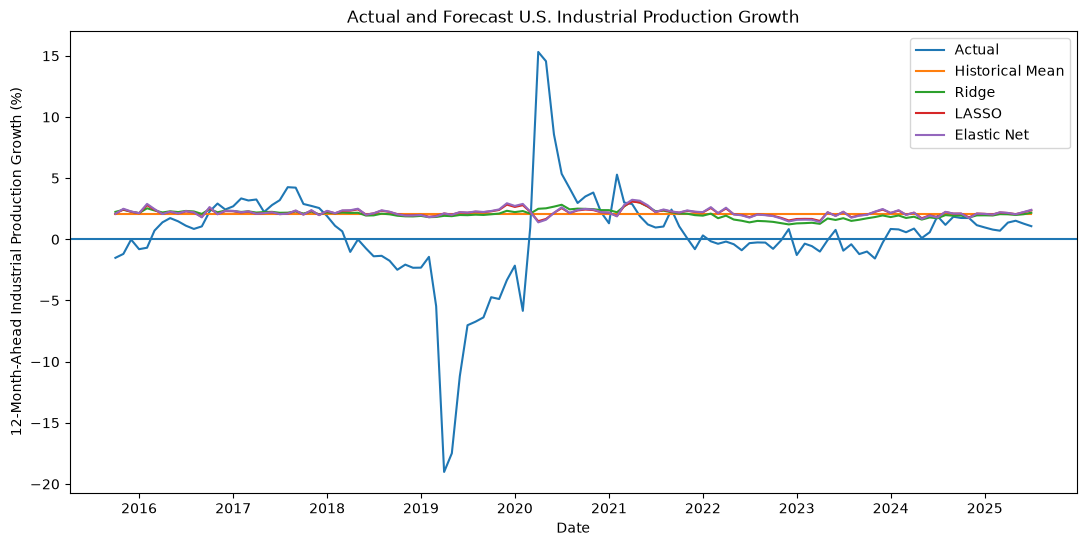

In [61]:
plt.figure(figsize=(13, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual"
)

plt.plot(
    y_test.index,
    historical_mean_pred,
    label="Historical Mean"
)

plt.plot(
    y_test.index,
    ridge_pred,
    label="Ridge"
)

plt.plot(
    y_test.index,
    lasso_pred,
    label="LASSO"
)

plt.plot(
    y_test.index,
    elastic_net_pred,
    label="Elastic Net"
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "12-Month-Ahead Industrial Production Growth (%)"
)

plt.title(
    "Actual and Forecast U.S. Industrial Production Growth"
)

plt.legend()

plt.show()

**Plot: Elastic Net Coefficients**

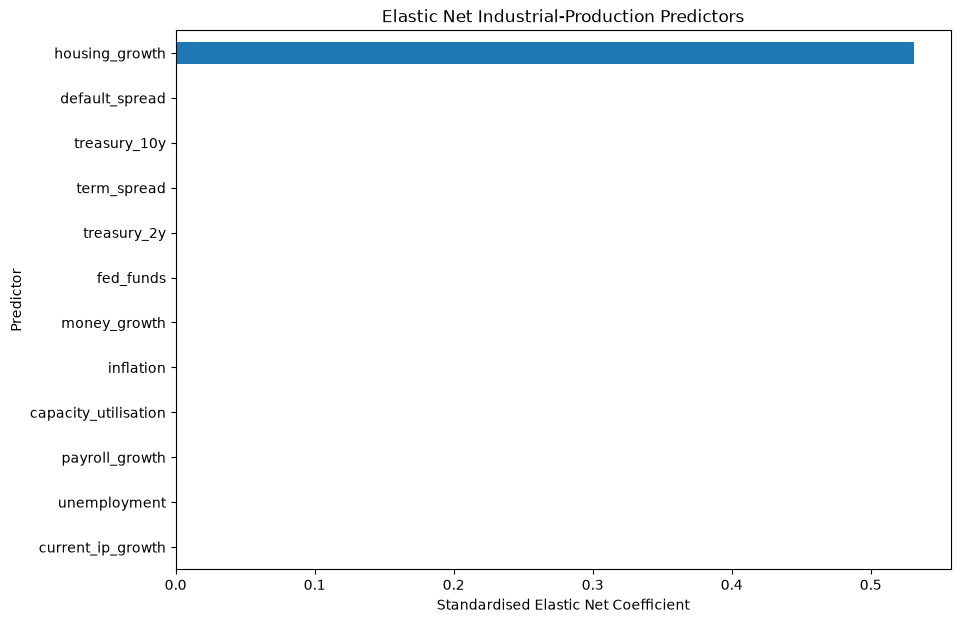

In [62]:
elastic_net_coefficients.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.axvline(
    x=0
)

plt.xlabel(
    "Standardised Elastic Net Coefficient"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Elastic Net Industrial-Production Predictors"
)

plt.show()

**Compare LASSO and Elastic Net Coefficients**

In [63]:
lasso_elastic_comparison = pd.DataFrame({
    "LASSO":
        lasso_coefficients,

    "Elastic_Net":
        elastic_net_coefficients
})

lasso_elastic_comparison.round(4)

,LASSO,Elastic_Net
current_ip_growth,0.0000,0.0000
unemployment,0.0000,0.0000
payroll_growth,0.0000,-0.0000
capacity_utilisation,0.0000,-0.0000
inflation,-0.0000,-0.0000
money_growth,0.0000,-0.0000
housing_growth,0.4604,0.5309
fed_funds,-0.0000,-0.0000
treasury_2y,0.0000,-0.0000
treasury_10y,0.0000,-0.0000


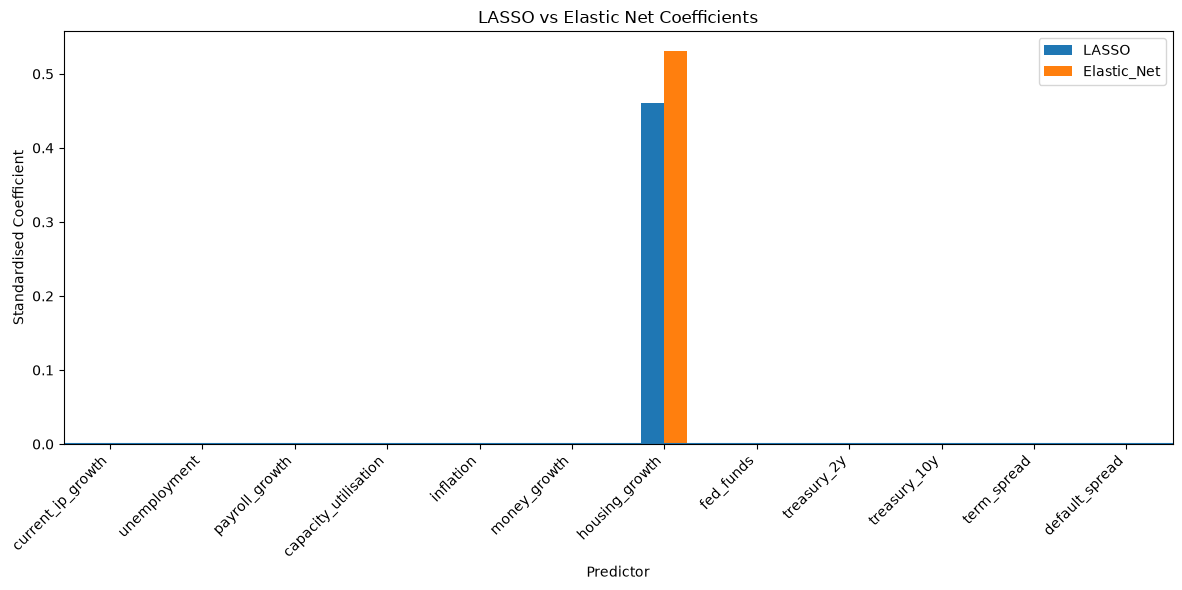

In [64]:
lasso_elastic_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Predictor"
)

plt.ylabel(
    "Standardised Coefficient"
)

plt.title(
    "LASSO vs Elastic Net Coefficients"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [65]:
path_scaler = StandardScaler()

X_train_path = (
    path_scaler.fit_transform(
        X_train
    )
)

path_alphas = np.logspace(
    -4,
    2,
    100
)

elastic_coefficient_path = []

for alpha in path_alphas:

    model = ElasticNet(
        alpha=alpha,
        l1_ratio=best_l1_ratio,
        max_iter=100000
    )

    model.fit(
        X_train_path,
        y_train
    )

    elastic_coefficient_path.append(
        model.coef_
    )

elastic_coefficient_path = np.array(
    elastic_coefficient_path
)

**Plot: Elastic Net Coefficient Paths**

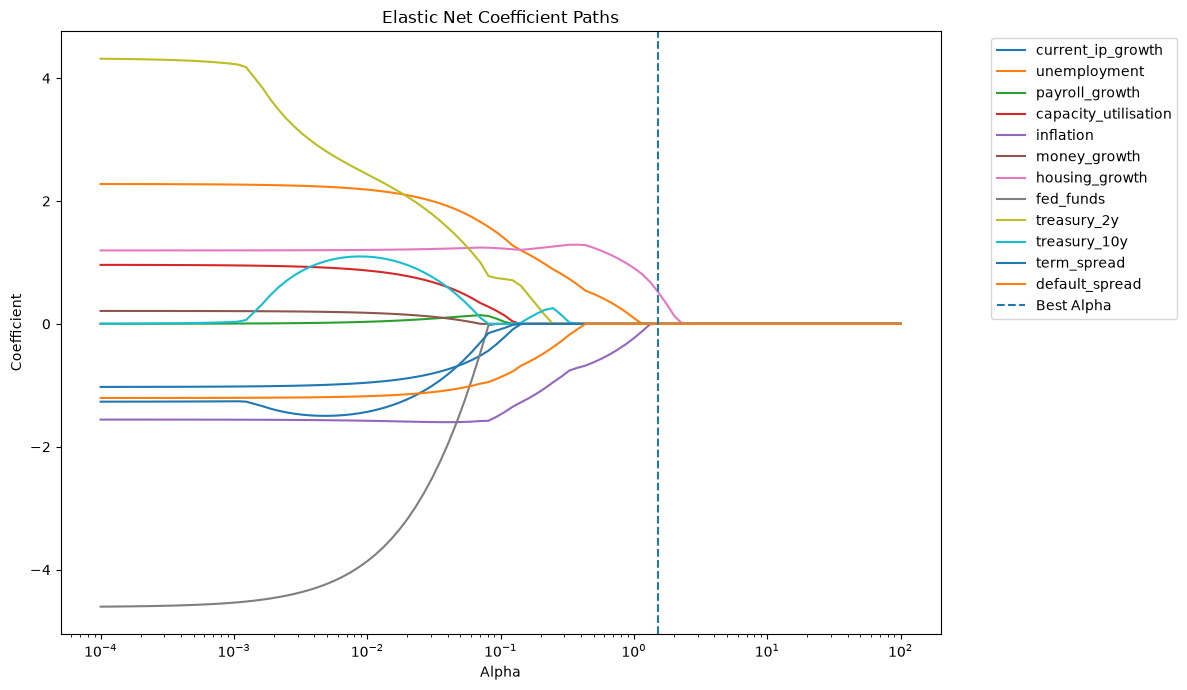

In [66]:
plt.figure(figsize=(12, 7))

for i, feature in enumerate(features):

    plt.semilogx(
        path_alphas,
        elastic_coefficient_path[:, i],
        label=feature
    )

plt.axvline(
    best_elastic_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Coefficient"
)

plt.title(
    "Elastic Net Coefficient Paths"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

In [67]:
elastic_cv_results = pd.DataFrame(
    elastic_net_search.cv_results_
)

elastic_cv_results[
    "RMSE"
] = (
    -elastic_cv_results[
        "mean_test_score"
    ]
)

elastic_cv_results[
    "alpha"
] = (
    elastic_cv_results[
        "param_elastic_net__alpha"
    ].astype(float)
)

elastic_cv_results[
    "l1_ratio"
] = (
    elastic_cv_results[
        "param_elastic_net__l1_ratio"
    ].astype(float)
)

**Plot: CV Error for Different l1_ratio Values**

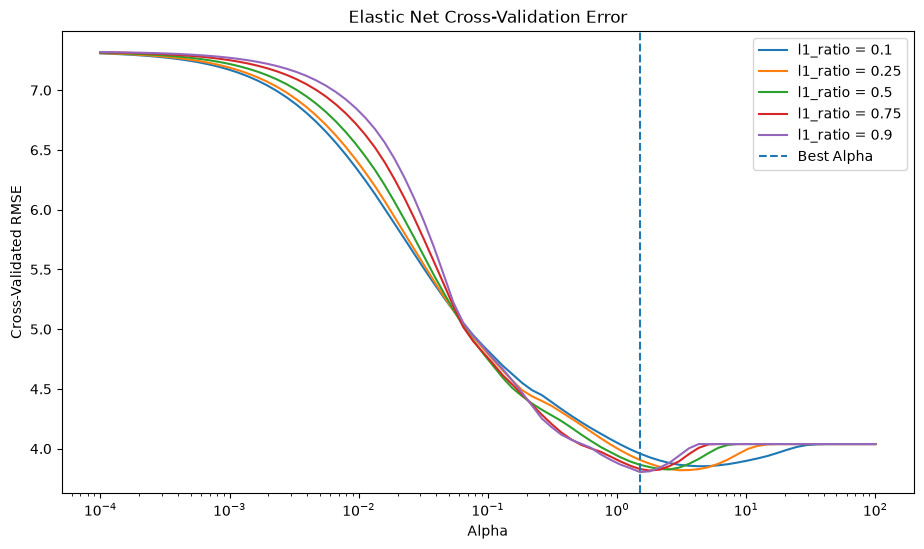

In [68]:
plt.figure(figsize=(11, 6))

for ratio in l1_ratio_values:

    ratio_results = (
        elastic_cv_results[
            elastic_cv_results[
                "l1_ratio"
            ] == ratio
        ]
        .sort_values(
            "alpha"
        )
    )

    plt.semilogx(
        ratio_results["alpha"],
        ratio_results["RMSE"],
        label=f"l1_ratio = {ratio}"
    )

plt.axvline(
    best_elastic_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Cross-Validated RMSE"
)

plt.title(
    "Elastic Net Cross-Validation Error"
)

plt.legend()

plt.show()

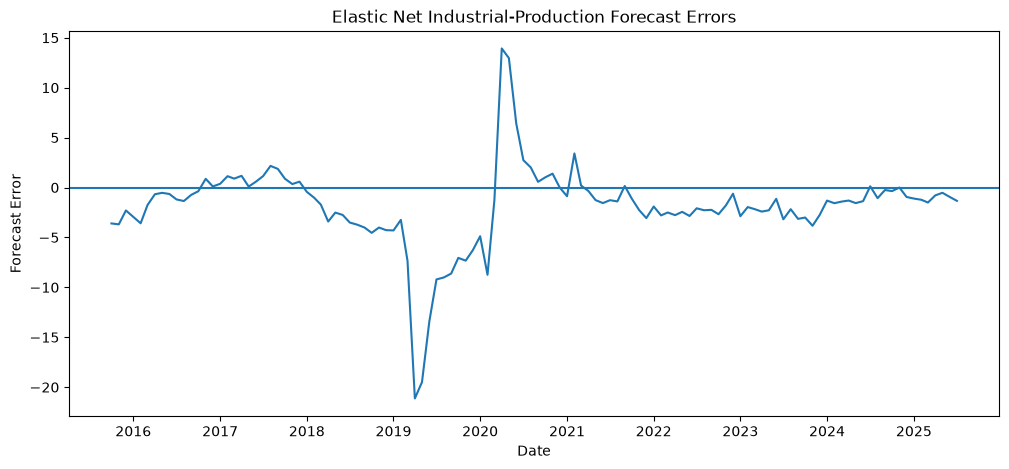

In [69]:
elastic_residuals = (
    y_test.values
    - elastic_net_pred
)

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    elastic_residuals
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Forecast Error"
)

plt.title(
    "Elastic Net Industrial-Production Forecast Errors"
)

plt.show()

**Cumulative Forecast Gain Relative to Historical Mean**

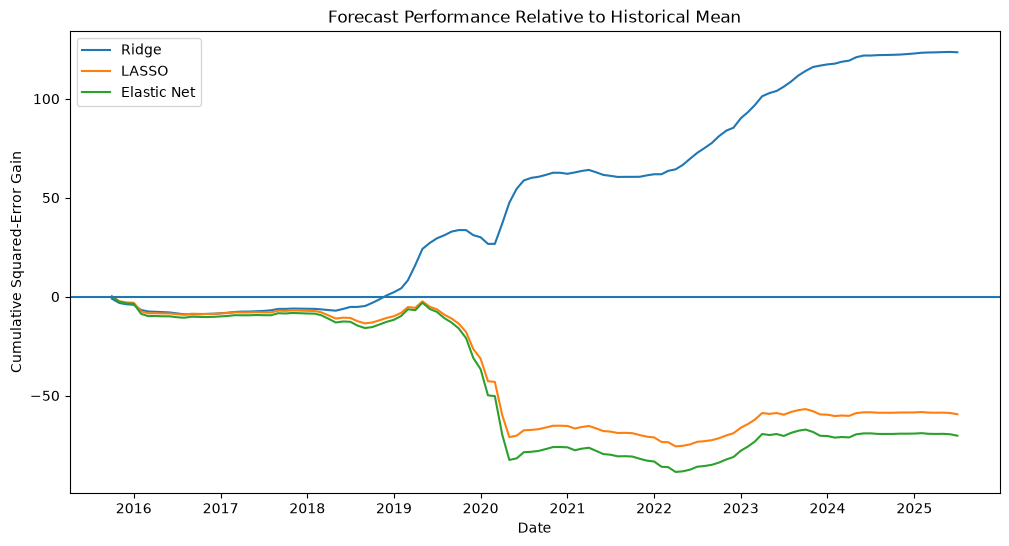

In [70]:
benchmark_squared_error = (
    y_test.values
    - historical_mean_pred
) ** 2

ridge_squared_error = (
    y_test.values
    - ridge_pred
) ** 2

lasso_squared_error = (
    y_test.values
    - lasso_pred
) ** 2

elastic_squared_error = (
    y_test.values
    - elastic_net_pred
) ** 2

ridge_cumulative_gain = np.cumsum(
    benchmark_squared_error
    - ridge_squared_error
)

lasso_cumulative_gain = np.cumsum(
    benchmark_squared_error
    - lasso_squared_error
)

elastic_cumulative_gain = np.cumsum(
    benchmark_squared_error
    - elastic_squared_error
)

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    ridge_cumulative_gain,
    label="Ridge"
)

plt.plot(
    y_test.index,
    lasso_cumulative_gain,
    label="LASSO"
)

plt.plot(
    y_test.index,
    elastic_cumulative_gain,
    label="Elastic Net"
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Cumulative Squared-Error Gain"
)

plt.title(
    "Forecast Performance Relative to Historical Mean"
)

plt.legend()

plt.show()

In [71]:
forecast_results = pd.DataFrame({
    "Actual":
        y_test,

    "Historical_Mean":
        historical_mean_pred,

    "OLS":
        ols_pred,

    "Ridge":
        ridge_pred,

    "LASSO":
        lasso_pred,

    "Elastic_Net":
        elastic_net_pred
})

forecast_results.head(10).round(3)

,Actual,Historical_Mean,OLS,Ridge,LASSO,Elastic_Net
DATE,,,,,,
2015-10-01,-1.514,2.102,1.108,2.244,2.087,2.085
2015-11-01,-1.193,2.102,2.546,2.412,2.445,2.498
2015-12-01,-0.020,2.102,1.709,2.256,2.255,2.278
2016-01-01,-0.806,2.102,0.551,2.145,2.132,2.136
2016-02-01,-0.689,2.102,2.601,2.539,2.790,2.896
2016-03-01,0.714,2.102,2.187,2.358,2.421,2.470
2016-04-01,1.390,2.102,1.313,2.196,2.071,2.066
2016-05-01,1.735,2.102,1.795,2.290,2.247,2.269
2016-06-01,1.469,2.102,1.483,2.227,2.115,2.117


In [72]:
forecast_results.tail(10).round(3)

,Actual,Historical_Mean,OLS,Ridge,LASSO,Elastic_Net
DATE,,,,,,
2024-10-01,1.744,2.102,-0.457,1.945,2.103,2.103
2024-11-01,1.739,2.102,-0.380,1.781,1.791,1.743
2024-12-01,1.156,2.102,0.239,1.957,2.104,2.105
2025-01-01,0.969,2.102,-0.479,1.962,2.080,2.077
2025-02-01,0.794,2.102,0.106,1.948,2.031,2.020
2025-03-01,0.704,2.102,0.327,2.059,2.195,2.209
2025-04-01,1.367,2.102,-0.510,2.047,2.150,2.157
2025-05-01,1.518,2.102,-0.397,1.990,2.055,2.048
2025-06-01,1.281,2.102,-0.339,2.050,2.212,2.229


In [73]:
performance.to_csv(
    "problem_14_model_performance.csv",
    index=False
)

coefficient_table.to_csv(
    "problem_14_coefficients.csv"
)

forecast_results.to_csv(
    "problem_14_forecasts.csv"
)

elastic_cv_results.to_csv(
    "problem_14_elastic_net_cv.csv",
    index=False
)

## END